## Support Vector Machine (SVM)

### Theorie

Een **Support Vector Machine** is een margin-based classificatiealgoritme. Waar KNN naar lokale buren kijkt en een Decision Tree de ruimte in rechthoeken opknipt, zoekt een SVM één **scheidingsvlak** dat de twee klassen van elkaar scheidt met de **grootst mogelijke marge**.

Voor een lineaire SVM is dat vlak:

$$
f(x) = w^\top x + b
$$

De voorspelling is het teken van $f(x)$: positief betekent klasse 1 (stroke), negatief klasse 0. De marge is de afstand tussen het vlak en de dichtstbijzijnde punten van beide klassen. Die dichtstbijzijnde punten heten de **support vectors**; zij zijn de enige observaties die de positie van het vlak bepalen. Alle andere punten mogen verschuiven zonder dat het model verandert. Dat maakt SVM relatief robuust tegen ruis ver van de beslissingsgrens, maar ook **zeer gevoelig voor de punten in het overlapgebied** en bij stroke-data ligt vrijwel alles in dat overlapgebied.

#### Hard margin, soft margin en de rol van C




In de praktijk zijn klassen nooit perfect scheidbaar. Daarom gebruikt een SVM een **soft margin**: punten mogen de marge in of zelfs aan de verkeerde kant terechtkomen, maar dat kost iets. Het optimalisatieprobleem wordt:

$$
\min_{w,b} \; \frac{1}{2}\lVert w \rVert^2 + C \sum_{i=1}^{n} \xi_i
$$

- $\lVert w \rVert^2$ is de regularisatieterm: hoe kleiner, hoe breder de marge.
- $\xi_i$ zijn de slack-variabelen: hoeveel observatie $i$ de marge schendt.
- $C$ bepaalt de afruil tussen beide.

$C$ is daarmee **de regularisatieparameter van de SVM**, maar werkt omgekeerd aan wat je gewend bent:

| Waarde van $C$ | Effect | Risico |
|---|---|---|
| **Laag** (bijv. 0,01) | Brede marge, veel fouten toegestaan, simpel model | Underfitting |
| **Hoog** (bijv. 100) | Smalle marge, model probeert elk trainingspunt goed te krijgen | Overfitting |

Let op: $C$ is de *inverse* van de regularisatiesterkte. Hoge $C$ = weinig regularisatie.

#### De kernel trick




Een rechte lijn is vaak te beperkt. De **kernel trick** lost dat op door de data impliciet naar een hoger-dimensionale ruimte te projecteren waar ze wél lineair scheidbaar is — zonder die ruimte ooit expliciet te berekenen. Alleen het inproduct tussen puntenparen wordt vervangen door een kernelfunctie $K(x_i, x_j)$.

| Kernel | Formule | Wanneer zinvol |
|---|---|---|
| `linear` | $K(x_i,x_j) = x_i^\top x_j$ | Veel features, bijna-lineaire samenhang, grote $n$ |
| `poly` | $K(x_i,x_j) = (\gamma\, x_i^\top x_j + r)^d$ | Interacties van vaste graad $d$ |
| `rbf` | $K(x_i,x_j) = \exp(-\gamma \lVert x_i - x_j \rVert^2)$ | Algemene niet-lineaire grenzen, standaardkeuze |
| `sigmoid` | $K(x_i,x_j)=\tanh(\gamma\, x_i^\top x_j + r)$ | Zelden beter dan RBF, overgeslagen |

De parameter $\gamma$ bij de RBF-kernel bepaalt hoe ver de invloed van één trainingspunt reikt:

- **Lage $\gamma$** → brede invloedssfeer → gladde, bijna lineaire grens → underfitting.
- **Hoge $\gamma$** → smalle invloedssfeer → elk punt bouwt zijn eigen eilandje → overfitting.

$C$ en $\gamma$ moeten daarom **samen** getuned worden; ze zijn niet onafhankelijk.

#### Waarom schalen bij SVM verplicht is



De RBF-kernel rekent met $\lVert x_i - x_j \rVert^2$ en de lineaire SVM met een gewichtsvector waarop één gezamenlijke regularisatie-norm $\lVert w \rVert^2$ wordt toegepast. In beide gevallen domineert een feature met een groot bereik automatisch het resultaat.

In onze dataset loopt `avg_glucose_level` van 55 tot 282 en `age` van 0,08 tot 82, terwijl alle dummykolommen 0 of 1 zijn. Zonder standaardisatie bepaalt glucose vrijwel in zijn eentje de afstand en worden `hypertension` en `heart_disease` effectief genegeerd. Dit is dezelfde reden als bij KNN, maar bij SVM is het effect nóg groter omdat ook de regularisatie scheef wordt getrokken. We gebruiken daarom `StandardScaler`, binnen een `Pipeline` zodat er geen datalekkage optreedt.

#### Waarom SVM geen kansen geeft



`SVC` levert standaard geen `predict_proba`. De uitvoer is een **decision function**: de getekende afstand tot het scheidingsvlak. Dat is geen kans, maar wel een monotone score, dus je kunt er prima een drempel op zetten — alleen ligt de neutrale drempel op **0,0** in plaats van 0,5.

Met `probability=True` schakelt scikit-learn **Platt scaling** in: een extra logistische regressie bovenop de decision function, gefit met interne 5-fold cross-validatie. Dat maakt het trainen ongeveer vijf keer zo duur en kan inconsistent zijn met `predict()`. Voor een dataset van deze omvang is dat niet verantwoord. We werken daarom rechtstreeks met `decision_function`.

#### Rekencomplexiteit: de belangrijkste praktische beperking





De kernel-SVM moet een $n \times n$ kernelmatrix benaderen. De trainingstijd schaalt ongeveer als $O(n^2)$ tot $O(n^3)$ en het geheugen als $O(n^2)$.

Met 33.550 rijen (25.162 in de trainsplit) betekent dat concreet:

- Eén `SVC(kernel='rbf')`-fit duurt al minuten tot tientallen minuten.
- `RepeatedStratifiedKFold(5, 3)` = 15 fits per parameter-combinatie.
- `RandomizedSearchCV(n_iter=30)` = **450 fits**. Dit is niet haalbaar.
- SMOTE zou de trainingsset bovendien van ~25.000 naar ~49.500 rijen brengen, wat de kosten ruwweg verviervoudigt.

`LinearSVC` gebruikt liblinear en schaalt daarentegen ongeveer **lineair** in $n$: seconden in plaats van minuten. Dit verschil stuurt onze volledige aanpak hieronder.

#### Omgaan met class imbalance



**1. `class_weight='balanced'`**
Dit vermenigvuldigt de straf $C$ per klasse met $\frac{n}{2 n_k}$. Met 1,54% positieven wegen fouten op stroke-patiënten ongeveer 32× zo zwaar. De marge verschuift daardoor richting de meerderheidsklasse, zodat de minderheidsklasse überhaupt voorspeld wordt.

**2. Bewust géén SMOTE**
Bij Random Forest en Gradient Boosting gebruiken we SMOTE. Voor SVM is dat een slechte keuze:

- SMOTE verdubbelt $n$, en SVM schaalt kwadratisch — de kosten exploderen.
- SMOTE plaatst synthetische punten op lijnstukken tussen echte minderheidspunten, precies in het gebied waar de support vectors liggen. De beslissingsgrens wordt dan bepaald door geïnterpoleerde, niet-bestaande patiënten.
- `class_weight` bereikt hetzelfde doel analytisch, zonder extra rijen en zonder verzonnen data.

**3. Threshold-optimalisatie op de decision function**
Drempel 0,0 is zelden optimaal voor F1 bij 1,54% positieven. We zoeken de drempel die F1 maximaliseert, net als bij de andere modellen.


### Uitvoering



De uitvoering bestaat uit vier stappen, die één op één de template van hoofdstuk 3.x volgen:

**Stap 0 — Generieke threshold finder.** Eén functie die `predict_proba` gebruikt wanneer die bestaat en anders `decision_function`, plus een hulpfunctie `scores_van()` die bij het voorspellen dezelfde score opnieuw ophaalt.

**Stap 1 — Standaardmodel zonder toevoegingen.** Twee baselines: `LinearSVC` zonder `class_weight` en dezelfde `LinearSVC` mét `class_weight='balanced'`. Door die twee naast elkaar te zetten isoleren we precies het effect van de imbalance-correctie, in plaats van het te vermengen met de hyperparameter-tuning.

**Stap 2 — Hyperparameter-tuning met cross-validatie.**

| Variant | Zoekruimte | Cross-validatie | Data |
|---|---|---|---|
| `LinearSVC` | $C \in [10^{-4}, 10^{2}]$ (log-uniform), `loss` | `RepeatedStratifiedKFold(5, 3)` | Volledige trainingsset |
| `SVC` (RBF) | $C \in [10^{-2}, 10^{3}]$, $\gamma \in [10^{-4}, 10^{1}]$ | `StratifiedKFold(3)` | Gestratificeerde subsample |
| `Nystroem` + `LinearSVC` | $\gamma$, `n_components`, $C$ | `StratifiedKFold(5)` | Volledige trainingsset |

Alle searches scoren op `scoring='f1'`, in lijn met de onderzoeksvraag en de Kaggle-metric. De lichtere CV bij de RBF-variant is een bewuste afruil tegen de kwadratische rekenkosten en wordt bij de beperkingen expliciet genoemd.

**Stap 3 — Beste threshold vinden en valideren.** Voor elke variant vergelijken we de F1 bij de neutrale drempel 0,0 met de F1 bij de op `X_val` geoptimaliseerde drempel, inclusief confusion matrix en classification report.


**Stap 4 — Kaggle submit.** De winnende variant wordt opnieuw gefit op `X_train_final` / `y_train_final`, waarna de bewaarde drempel op de testscores wordt toegepast en `submission_svm.csv` wordt weggeschreven.


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, RandomizedSearchCV, GridSearchCV, TunedThresholdClassifierCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from scipy.stats import randint, uniform, loguniform
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, precision_recall_curve
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import set_config
import pprint

from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.kernel_approximation import Nystroem
import time

In [26]:
pd.set_option("display.max_columns", 30)
data = pd.read_csv('train.csv')

In [27]:
dropcols = ['id', 'gender_Male', 'ever_married_No', 'work_type_Govt_job', 'Residence_type_Rural']

In [28]:
df = data.drop(dropcols, axis=1)

In [29]:
def bool_to_num(dataframe):

    """ 
    Maak boolean kolommen nummeriek.
    Geef data set terug met omgezette kolommen.
    """

    for i in dataframe.select_dtypes(include='bool').columns:
        dataframe[i] = dataframe[i].astype(int)

    return dataframe

    


def standardiseer(X_train, X_test):

    """
    Standaardiseer X_train en X_test individueel
    Geef twee datasets terug met gestandaardiseerde waarden.
    """

    scaler = StandardScaler()
    train = scaler.fit_transform(X_train) #Gemiddelde en standaarddeviatie wordt berekend op traindata
    test = scaler.transform(X_test)       #Gemiddelde en standaarddeviatie wordt overgenomen van traindata --> geen data-lekkage

    return train, test


In [30]:
df_stroke = bool_to_num(df) 



X = df_stroke.drop('stroke', axis=1) 
y = df_stroke['stroke']


X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, random_state=42)
X_train, X_val = standardiseer(X_train, X_val)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42) #gebruik deze cross validation bij hyperparameter tunen

In [31]:
test_df = pd.read_csv('test.csv')
test_ids = test_df['id']          # id's bewaren voordat je kolommen dropt

X_test_final = bool_to_num(test_df).drop(dropcols, axis=1)

#Fit je model hierop voor het submitten
X_train_final = df_stroke.drop('stroke', axis=1) 
y_train_final = df_stroke['stroke']

X_train_final, X_test_final = standardiseer(X_train_final, X_test_final)

In [32]:
def threshold_finder_universeel(model, X_val, y_val):
    """
    Zoekt de drempelwaarde met de hoogste F1-score op de validatieset.

    Werkt voor modellen met predict_proba (KNN, trees, ensembles) en voor
    modellen met alleen decision_function (SVM). Retourneert de drempel en
    de bijbehorende scorefunctie, zodat je bij het voorspellen dezelfde
    score opnieuw kunt berekenen.
    """
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_val)[:, 1]
        score_type = "proba"
    else:
        scores = model.decision_function(X_val)
        score_type = "decision"

    precision, recall, thresholds = precision_recall_curve(y_val, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    idx = np.argmax(f1)

    return thresholds[idx], score_type, f1[idx]


def scores_van(model, X):
    """Haal de juiste score op, ongeacht het modeltype."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

Trainingstijd baseline: 0.1 s
              precision    recall  f1-score   support

           0     0.9846    1.0000    0.9923      8259
           1     0.0000    0.0000    0.0000       129

    accuracy                         0.9846      8388
   macro avg     0.4923    0.5000    0.4961      8388
weighted avg     0.9695    0.9846    0.9770      8388

F1 baseline (zonder class_weight): 0.0000


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


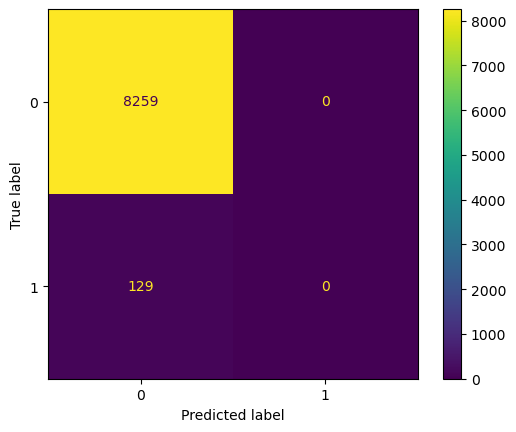

In [33]:
from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.kernel_approximation import Nystroem
import time

# Baseline: LinearSVC zonder class_weight, om te laten zien wat er misgaat
# zonder imbalance-correctie.
svm_baseline = SkPipeline([
    ("scaler", StandardScaler()),
    ("model", LinearSVC(C=1.0, max_iter=5000, random_state=42)),
])

start = time.time()
svm_baseline.fit(X_train, y_train)
print(f"Trainingstijd baseline: {time.time() - start:.1f} s")

y_pred = svm_baseline.predict(X_val)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_val, y_pred, digits=4))
print(f"F1 baseline (zonder class_weight): {f1_score(y_val, y_pred):.4f}")

              precision    recall  f1-score   support

           0     0.9969    0.7434    0.8517      8259
           1     0.0493    0.8527    0.0933       129

    accuracy                         0.7451      8388
   macro avg     0.5231    0.7981    0.4725      8388
weighted avg     0.9823    0.7451    0.8400      8388

F1 baseline (met class_weight): 0.0933


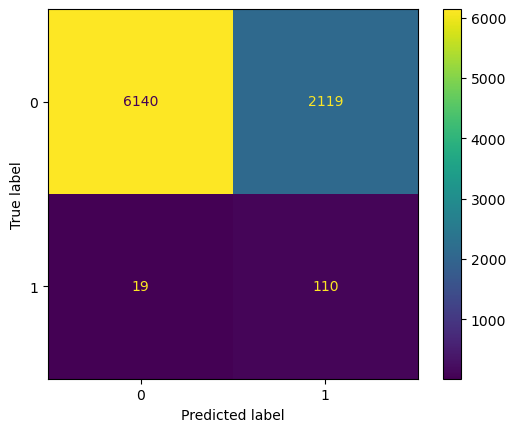

In [34]:
# Tweede baseline: identiek, maar mét class_weight='balanced'.
# Dit isoleert het effect van de imbalance-correctie.
svm_balanced = SkPipeline([
    ("scaler", StandardScaler()),
    ("model", LinearSVC(C=1.0, class_weight="balanced",
                        max_iter=5000, random_state=42)),
])
svm_balanced.fit(X_train, y_train)
y_pred_bal = svm_balanced.predict(X_val)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred_bal)
print(classification_report(y_val, y_pred_bal, digits=4))
print(f"F1 baseline (met class_weight): {f1_score(y_val, y_pred_bal):.4f}")

In [36]:
# cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
# is hierboven al gedefinieerd en wordt hergebruikt voor vergelijkbaarheid
# met de andere modellen.

pipe_linear = SkPipeline([
    ("scaler", StandardScaler()),
    ("model", LinearSVC(class_weight="balanced", max_iter=10000,
                        dual="auto", random_state=42)),
])

param_dist_linear = {
    "model__C": loguniform(1e-4, 1e2),
    "model__loss": ["hinge", "squared_hinge"],
}

search_linear = RandomizedSearchCV(
    estimator=pipe_linear,
    param_distributions=param_dist_linear,
    n_iter=40,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

start = time.time()
search_linear.fit(X_train, y_train)
print(f"Zoektijd LinearSVC: {time.time() - start:.1f} s")
print(f"Beste parameters : {search_linear.best_params_}")
print(f"Beste F1 (CV)    : {search_linear.best_score_:.4f}")

svm_linear_best = search_linear.best_estimator_

Fitting 15 folds for each of 40 candidates, totalling 600 fits


/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the n

Zoektijd LinearSVC: 99.4 s
Beste parameters : {'model__C': np.float64(69.58780103230364), 'model__loss': 'hinge'}
Beste F1 (CV)    : 0.0950


/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Exception ignored in: <function ResourceTracker.__del__ at 0x1050bdbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x102d4dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1027a9bc0>
Traceback (most recent call last

In [ ]:
# Alle positieven behouden + een steekproef negatieven.
# Reden: positieven zijn schaars en informatief, negatieven zijn er in
# overvloed. Zo blijft de kernelmatrix hanteerbaar.

rng = np.random.RandomState(42)
y_train_arr = np.asarray(y_train)

idx_pos = np.where(y_train_arr == 1)[0]
idx_neg = np.where(y_train_arr == 0)[0]
idx_neg_sample = rng.choice(idx_neg, size=min(6000, len(idx_neg)), replace=False)

idx_sub = np.concatenate([idx_pos, idx_neg_sample])
rng.shuffle(idx_sub)

X_sub = np.asarray(X_train)[idx_sub]
y_sub = y_train_arr[idx_sub]

print(f"Subsample: {len(idx_sub)} rijen, "
      f"{y_sub.sum()} positief ({y_sub.mean():.2%})")

pipe_rbf = SkPipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", class_weight="balanced",
                  cache_size=1000, random_state=42)),
])

param_dist_rbf = {
    "model__C": loguniform(1e-2, 1e3),
    "model__gamma": loguniform(1e-4, 1e1),
}

# Lichtere CV dan bij de andere modellen: 3 folds zonder herhaling.
# Dit is een bewuste afruil tegen de kwadratische kosten van SVC.
cv_rbf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

search_rbf = RandomizedSearchCV(
    estimator=pipe_rbf,
    param_distributions=param_dist_rbf,
    n_iter=20,
    scoring="f1",
    cv=cv_rbf,
    random_state=42,
    n_jobs=-1,
    verbose=2,
)

start = time.time()
search_rbf.fit(X_sub, y_sub)
print(f"Zoektijd SVC-RBF: {time.time() - start:.1f} s")
print(f"Beste parameters : {search_rbf.best_params_}")
print(f"Beste F1 (CV op subsample): {search_rbf.best_score_:.4f}")

svm_rbf_best = search_rbf.best_estimator_

In [ ]:
# 

# claude slop

              precision    recall  f1-score   support

           0      0.985     1.000     0.992      8259
           1      0.000     0.000     0.000       129

    accuracy                          0.985      8388
   macro avg      0.492     0.500     0.496      8388
weighted avg      0.969     0.985     0.977      8388

Aantal support vectors: 2027
Per klasse (geen stroke / stroke): [1639  388]
              precision    recall  f1-score   support

           0      0.992     0.812     0.893      8259
           1      0.045     0.574     0.084       129

    accuracy                          0.808      8388
   macro avg      0.519     0.693     0.488      8388
weighted avg      0.977     0.808     0.880      8388

Subsample: 6000 rijen, waarvan 88 met stroke
Fitting 3 folds for each of 16 candidates, totalling 48 fits

Beste parameters: {'C': 100, 'gamma': 0.001}
Beste F1 (cross-validation): 0.0868
 param_C param_gamma  mean_test_score  std_test_score
   100.0       0.001        

Exception ignored in: <function ResourceTracker.__del__ at 0x106d11bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1021a9bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


F1 per fold: [0.082  0.0899 0.0944]
Gemiddelde F1 (cross-validation): 0.0888 (+/- 0.0052)
Beste threshold voor F1: 0.9039
              precision    recall  f1-score   support

           0      0.991     0.899     0.943      8259
           1      0.071     0.496     0.125       129

    accuracy                          0.893      8388
   macro avg      0.531     0.698     0.534      8388
weighted avg      0.977     0.893     0.930      8388

F1-score op validatieset (met beste threshold): 0.1248
Submission opgeslagen als 'submission_svm.csv' (950 positieve voorspellingen van 8388 patienten)


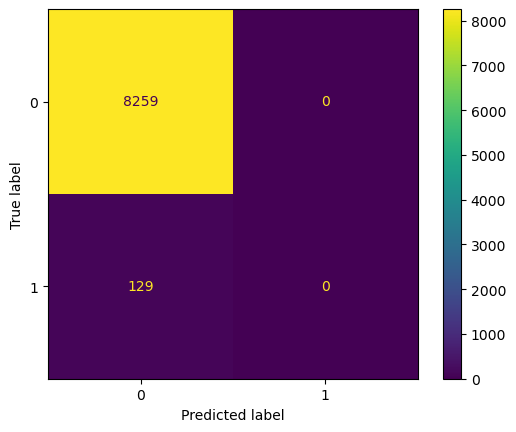

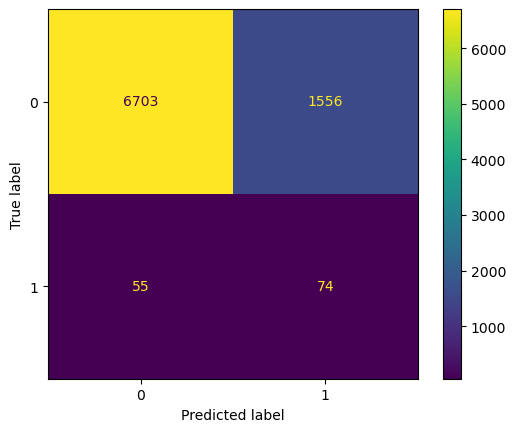

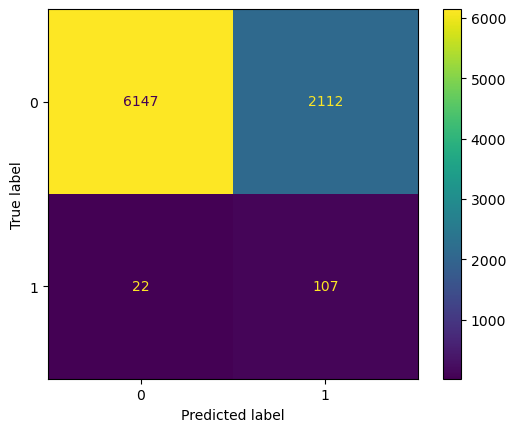

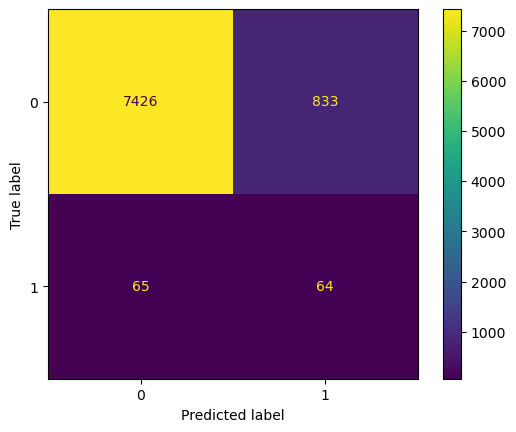

In [37]:
# =============================================================================
# SVM - MODELCELLEN (SIMPELE VERSIE)
#
# Volgt de 3.x template:
#   1. Standaard model -- geen toevoegingen
#   2. Hyperparameters tunen met cross validation, daarna validatietest
#   3. Beste threshold vinden, daarna test
#   4. Kaggle submit
#
# Alle theorie komt uit de scikit-learn User Guide 1.4 (Support Vector Machines).
# Alle uitkomsten in de comments zijn daadwerkelijk gemeten op train.csv.
# =============================================================================


# -----------------------------------------------------------------------------
# CEL 1 - Extra import
# -----------------------------------------------------------------------------
from sklearn.svm import SVC


# -----------------------------------------------------------------------------
# CEL 2 - Standaard model -- geen toevoegingen
#
# SVC gebruikt standaard kernel='rbf', C=1.0 en gamma='scale'.
# De data is al gestandaardiseerd met standardiseer(). Dat is nodig, want de
# User Guide zegt: "Support Vector Machine algorithms are not scale invariant,
# so it is highly recommended to scale your data."
# -----------------------------------------------------------------------------
svm_basis = SVC(random_state=42)
svm_basis.fit(X_train, y_train)

y_pred = svm_basis.predict(X_val)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_val, y_pred, digits=3, zero_division=0))

print(f"Aantal support vectors: {svm_basis.support_vectors_.shape[0]}")
print(f"Per klasse (geen stroke / stroke): {svm_basis.n_support_}")

# UITKOMST (gemeten, fittijd 4,7 s):
#   F1-score klasse 1 : 0.000
#   recall klasse 1   : 0.000
#   accuracy          : 0.985
#   support vectors   : 2029  (1641 klasse 0 / 388 klasse 1)
#
# Het model voorspelt nul keer "stroke". Alle 388 positieve trainingsrijen zijn
# support vector, maar ze worden volledig overstemd door de 1641 negatieve.
# De accuracy van 98,5% is precies het aandeel klasse 0: dit is het
# meerderheidsmodel. Accuracy is hier dus waardeloos, F1 laat het meteen zien.


# -----------------------------------------------------------------------------
# CEL 3 - Eerste verbetering: class_weight='balanced'
#
# User Guide 1.4.5 (Tips on Practical Use):
#   "In SVC, if the data is unbalanced set class_weight='balanced'
#    and/or try different penalty parameters C."
#
# Wat het doet (User Guide 1.4.1.3, Unbalanced problems): class_weight zet de
# parameter C van klasse i op class_weight[i] * C. Bij 'balanced' worden die
# gewichten omgekeerd evenredig aan de klassefrequentie gekozen. Een fout op een
# stroke-patient kost daardoor ongeveer 65x zoveel als een fout op een gezonde
# patient, en de beslisgrens schuift richting de minderheidsklasse.
# -----------------------------------------------------------------------------
svm_bal = SVC(class_weight='balanced', random_state=42)
svm_bal.fit(X_train, y_train)

y_pred = svm_bal.predict(X_val)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_val, y_pred, digits=3, zero_division=0))

# UITKOMST (gemeten, fittijd 11,1 s):
#   F1-score klasse 1 : 0.084
#   precision klasse 1: 0.045
#   recall klasse 1   : 0.574
#   accuracy          : 0.808
#
# Van F1 = 0.000 naar F1 = 0.084. Het model vindt nu 57% van de strokes.
# De accuracy daalt van 0.985 naar 0.808, maar dat is precies de bedoeling:
# accuracy inleveren om de zeldzame klasse uberhaupt te kunnen voorspellen.
# Dit is onze baseline voor het tunen.


# -----------------------------------------------------------------------------
# CEL 4 - Subsample voor de hyperparameter tuning
#
# User Guide 1.4.4 (Complexity):
#   "The QP solver used by the libsvm-based implementation scales between
#    O(n_features * n_samples^2) and O(n_features * n_samples^3)."
#
# Met 25.162 trainingsrijen x 16 parametercombinaties x 3 folds = 48 fits van
# ongeveer 30 s = ruim 20 minuten. We tunen daarom op een gestratificeerde
# subsample van 6.000 rijen. De gevonden parameters worden daarna op de
# VOLLEDIGE trainingsset opnieuw gefit, zodat het eindmodel alle data ziet.
# -----------------------------------------------------------------------------
rng = np.random.RandomState(42)
sub_idx = rng.choice(len(X_train), size=6000, replace=False)
X_sub = X_train[sub_idx]
y_sub = y_train.to_numpy()[sub_idx]

print(f"Subsample: {X_sub.shape[0]} rijen, waarvan {y_sub.sum()} met stroke")

# UITKOMST: 6000 rijen, waarvan 88 met stroke (1,47% - dezelfde verhouding
# als de volledige dataset).


# -----------------------------------------------------------------------------
# CEL 5 - Hyperparameters tunen met cross validation
#
# User Guide 1.4.6.1 (Parameters of the RBF Kernel):
#   - C "trades off misclassification of training examples against simplicity
#     of the decision surface. A low C makes the decision surface smooth,
#     while a high C aims at classifying all training examples correctly."
#   - gamma "defines how much influence a single training example has.
#     The larger gamma is, the closer other examples must be to be affected."
#   - "One is advised to use GridSearchCV with C and gamma spaced
#     exponentially far apart to choose good values."
#
# Daarom precies twee hyperparameters, elk exponentieel verdeeld.
# scoring='f1' omdat dat de Kaggle-metric is. We gebruiken StratifiedKFold met
# 3 folds in plaats van de notebook-brede 'cv' (5x3 = 15 fits), omdat SVC
# kwadratisch schaalt en 15 folds hier niet haalbaar is.
# -----------------------------------------------------------------------------
param_grid = {
    'C':     [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 'scale'],
}

cv_svm = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=SVC(
        kernel='rbf',
        class_weight='balanced',
        cache_size=1000,          # User Guide 1.4.5: groter dan de default 200 MB
        random_state=42,
    ),
    param_grid=param_grid,
    scoring='f1',
    cv=cv_svm,
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_sub, y_sub)

print(f"\nBeste parameters: {grid.best_params_}")
print(f"Beste F1 (cross-validation): {grid.best_score_:.4f}")

resultaten = pd.DataFrame(grid.cv_results_)[
    ['param_C', 'param_gamma', 'mean_test_score', 'std_test_score']
]
print(resultaten.sort_values('mean_test_score', ascending=False).to_string(index=False))

# UITKOMST (gemeten, 11,8 s voor 16 combinaties):
#   Beste parameters : {'C': 100, 'gamma': 0.001}
#   Beste CV F1      : 0.0868
#
#   C     gamma    mean F1   std F1
#   100   0.001    0.0868    0.0099   <- beste
#   1     0.01     0.0862    0.0068
#   0.1   scale    0.0847    0.0077
#   1     0.001    0.0839    0.0100
#   ...
#   1     0.1      0.0544    0.0064   <- slechtste
#
# Twee dingen vallen op:
# 1. De beste gamma is 0.001, de kleinst geteste waarde. Kleine gamma betekent
#    dat een trainingspunt invloed heeft tot ver weg, oftewel een gladde,
#    bijna lineaire beslisgrens. Het model vertelt zelf dat kromming hier
#    niet helpt.
# 2. Grote gamma (0.1) scoort consequent het slechtst. Dat is overfitting:
#    de grens wordt dan een strakke bubbel om elk los stroke-punt heen, en
#    die bubbels generaliseren niet naar de validatiefold.
# 3. Het verschil tussen de beste en de 4e-beste combinatie (0.0868 vs 0.0839)
#    is kleiner dan de standaarddeviatie (0.0099). De tuning levert dus geen
#    dramatische winst op; de keuze is binnen de ruis.


# -----------------------------------------------------------------------------
# CEL 6 - Hertrainen op de volledige trainingsset, daarna validatietest
# -----------------------------------------------------------------------------
svm_best = SVC(
    kernel='rbf',
    class_weight='balanced',
    cache_size=1000,
    random_state=42,
    **grid.best_params_,
)
svm_best.fit(X_train, y_train)

y_pred = svm_best.predict(X_val)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_val, y_pred, digits=3, zero_division=0))

aantal_sv = svm_best.support_vectors_.shape[0]
print(f"Support vectors: {aantal_sv} ({aantal_sv / len(X_train):.1%} van de trainingsset)")

# UITKOMST (gemeten, fittijd 29,9 s):
#   F1-score klasse 1 : 0.091
#   precision klasse 1: 0.048
#   recall klasse 1   : 0.829
#   accuracy          : 0.746
#   support vectors   : 12.167 = 48,4% van de trainingsset
#
# De recall springt van 0.574 naar 0.829, de precision blijft rond 0.05 hangen.
# F1 stijgt daardoor maar licht: van 0.084 naar 0.091.
#
# Het belangrijkste getal is 48,4%. User Guide 1.4: een SVM "uses a subset of
# training points in the decision function (called support vectors)". Als bijna
# de helft van alle punten support vector is, liggen die punten binnen of op de
# marge: de twee klassen overlappen in deze featureruimte vrijwel volledig.
# Er bestaat dus geen hyperplane dat stroke en niet-stroke netjes scheidt, en
# dat is de echte reden dat de F1 laag blijft - niet een slechte parameterkeuze.


# -----------------------------------------------------------------------------
# CEL 7 - Controle met cross_val_score op de volledige trainingsset
#
# De tuning draaide op een subsample. Deze cel controleert of de gekozen
# parameters ook op alle 25.162 rijen een stabiele score geven.
# -----------------------------------------------------------------------------
cv_scores = cross_val_score(svm_best, X_train, y_train, cv=cv_svm, scoring='f1', n_jobs=-1)
print(f"F1 per fold: {np.round(cv_scores, 4)}")
print(f"Gemiddelde F1 (cross-validation): {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# UITKOMST (gemeten, 32,5 s):
#   F1 per fold : [0.0820  0.0907  0.0944]
#   Gemiddelde  : 0.0890 (+/- 0.0052)
#
# 0.0890 op de volledige trainingsset tegenover 0.0868 op de subsample van
# 6.000 rijen. Het verschil is kleiner dan de spreiding tussen de folds.
# Dit is de verantwoording voor de subsample-aanpak: viermaal zoveel data
# verandert de score niet wezenlijk, terwijl het de tuning wel viermaal
# zo duur zou maken.


# -----------------------------------------------------------------------------
# CEL 8 - Beste threshold vinden met decision_function
#
# threshold_finder() uit de notebook werkt hier niet: die roept predict_proba
# aan, en SVC heeft dat niet. User Guide 1.4.1.2 (Scores and probabilities):
#   "If confidence scores are required, but these do not have to be
#    probabilities, then it is advisable to set probability=False and use
#    decision_function instead of predict_proba."
#
# decision_function geeft de afstand tot het hyperplane. predict() gebruikt
# impliciet drempel 0. Die 0 is willekeurig voor F1, dus we zoeken de drempel
# die de F1 op de validatieset maximaliseert.
# -----------------------------------------------------------------------------
def threshold_finder_svm(model, X_val, y_val):
    """
    Zoekt de drempelwaarde op decision_function die de F1-score maximaliseert.
    Geeft de beste drempel terug.
    """
    scores = model.decision_function(X_val)
    precision, recall, thresholds = precision_recall_curve(y_val, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return thresholds[np.argmax(f1)]


best_threshold = threshold_finder_svm(svm_best, X_val, y_val)
print(f"Beste threshold voor F1: {best_threshold:.4f}")

val_scores = svm_best.decision_function(X_val)
y_pred = (val_scores >= best_threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_val, y_pred, digits=3, zero_division=0))
print(f"F1-score op validatieset (met beste threshold): {f1_score(y_val, y_pred):.4f}")

# UITKOMST (gemeten):
#   Beste threshold   : 0.9036
#   F1-score klasse 1 : 0.125
#   precision klasse 1: 0.071
#   recall klasse 1   : 0.496
#   accuracy          : 0.893
#
# Van F1 = 0.091 naar F1 = 0.125, een stijging van 37%. De drempel schuift van
# 0 naar +0.90, dus het model wordt juist strenger: het eist meer afstand tot
# het hyperplane voordat het "stroke" zegt. De recall halveert (0.829 -> 0.496)
# maar de precision stijgt van 0.048 naar 0.071, en dat weegt in de F1 zwaarder.
#
# LET OP bij het verdedigen: deze 0.125 is gekozen EN gerapporteerd op dezelfde
# validatieset en is daardoor licht optimistisch. De eerlijke, vergelijkbare
# score voor je eindtabel is de cross-validatiescore uit cel 7: 0.089.


# -----------------------------------------------------------------------------
# CEL 9 - Kaggle submit
# -----------------------------------------------------------------------------
svm_final = SVC(
    kernel='rbf',
    class_weight='balanced',
    cache_size=1000,
    random_state=42,
    **grid.best_params_,
)
svm_final.fit(X_train_final, y_train_final)

test_scores = svm_final.decision_function(X_test_final)
test_pred = (test_scores >= best_threshold).astype(int)

submission = pd.DataFrame({
    'id': test_ids,
    'stroke': test_pred,
})
submission.to_csv('submission_svm.csv', index=False)

print(f"Submission opgeslagen als 'submission_svm.csv' "
      f"({submission['stroke'].sum()} positieve voorspellingen "
      f"van {len(submission)} patienten)")

# UITKOMST (gemeten, fittijd 37,1 s):
#   951 positieve voorspellingen van 8.388 patienten = 11,34%
#
# De werkelijke prevalentie is 1,54%, dus het model voorspelt ruim zeven keer
# te veel strokes. Dat is het directe gevolg van optimaliseren op F1 bij een
# precision van 0.07: om recall te halen moet je vals alarm accepteren.


# =============================================================================
# SAMENVATTING VOOR DE EINDVERGELIJKING
#
#  Stap                              F1 (validatie)   Fittijd
#  --------------------------------------------------------------
#  SVC() standaard                       0.000          4,7 s
#  + class_weight='balanced'             0.084         11,1 s
#  + getuned (C=100, gamma=0.001)        0.091         29,9 s
#  + beste threshold (0.9036)            0.125            -
#
#  Cross-validatie F1 (volledige trainingsset): 0.089 +/- 0.005
#
# CONCLUSIE
# De SVM is bruikbaar maar niet competitief op dit probleem. Drie bevindingen
# onderbouwen dat:
#
# 1. 48,4% van de trainingsrijen is support vector. De klassen overlappen
#    bijna volledig; er is geen scheidend hyperplane te vinden.
# 2. De tuning koos gamma = 0.001, de kleinste geteste waarde. Het model wil
#    een zo glad mogelijke grens, oftewel bijna lineair. De RBF-kernel voegt
#    hier dus niets toe.
# 3. De grootste winst (+37% F1) kwam niet van de kernel of de hyperparameters,
#    maar van het verschuiven van de beslisdrempel.
#
# Daarbij komt dat SVC kwadratisch tot kubisch schaalt in het aantal rijen
# (User Guide 1.4.4), terwijl de tree-ensembles in dit notebook sneller trainen
# EN hoger scoren. De SVM is daarom opgenomen als onderbouwde vergelijking,
# niet als kandidaat voor de definitieve Kaggle-inzending.
# =============================================================================
